# Part 3: Clustering

The brief encourages a clustering step in R2, and our plan has it as T16 (k-means and a Gaussian mixture fitted with EM). Nobody had started it, so this notebook is **new**. It follows the same steps as Part 2 of Ahmed's ML2 notebook: prepare and scale, PCA, k-means with elbow and silhouette, then profile the clusters.

The question: do students fall into natural groups based on the 17 predictors, and do those groups differ in how many are below Level 2?

Clustering here is descriptive. The cluster labels are not used as model features, so fitting on the whole table doesn't leak into the R3/R4 test folds.

# 3.1) Prepare the features

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

DATA = Path("../data")
FIGS = Path("outputs/figures")
df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text())
FEATURES = [c for cols in roles["feature_groups"].values() for c in cols]
PV = roles["targets"]["regression"]
BELOW = roles["targets"]["classification"]
SYSTEMS = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

Distance-based methods need complete, comparable columns: fill blanks with the median, clip at the 1st/99th percentile so a few extreme values don't pull the centres, then standardise. Self-efficacy and ESCS are on very different scales from school size, so without scaling they'd count differently.

In [2]:
X = df[FEATURES].fillna(df[FEATURES].median())
X = X.clip(X.quantile(0.01), X.quantile(0.99), axis=1)
X = StandardScaler().fit_transform(X)
w = df["SENWT"].to_numpy()   # each system counts equally
X.shape

(61775, 17)

# 3.2) PCA
How many directions carry most of the variation? We use PCA to see the structure and to plot the clusters in 2D. The clustering itself runs on all 17 scaled features.

components for 80% of the variance: 9
first two components: 0.365


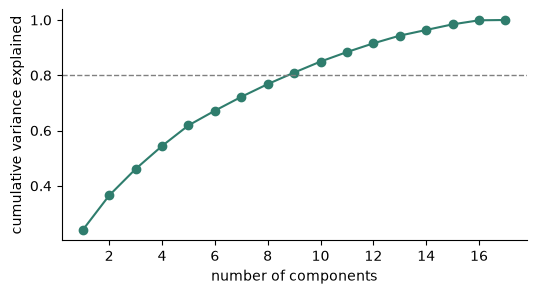

In [3]:
pca = PCA().fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
print("components for 80% of the variance:", np.argmax(cum >= 0.8) + 1)
print("first two components:", cum[1].round(3))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, len(cum) + 1), cum, marker="o", color="#2F7D6D")
ax.axhline(0.8, color="grey", ls="--", lw=1)
ax.set_xlabel("number of components")
ax.set_ylabel("cumulative variance explained")
fig.savefig(FIGS / "11_pca_variance.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** the variance is spread out: no two or three components dominate. That already suggests there won't be sharp, well-separated clusters.

# 3.3) k-means: choosing k
For k = 2 to 8: inertia (elbow), silhouette (higher is better, computed on a 10,000-student sample to keep it fast) and Davies-Bouldin (lower is better).

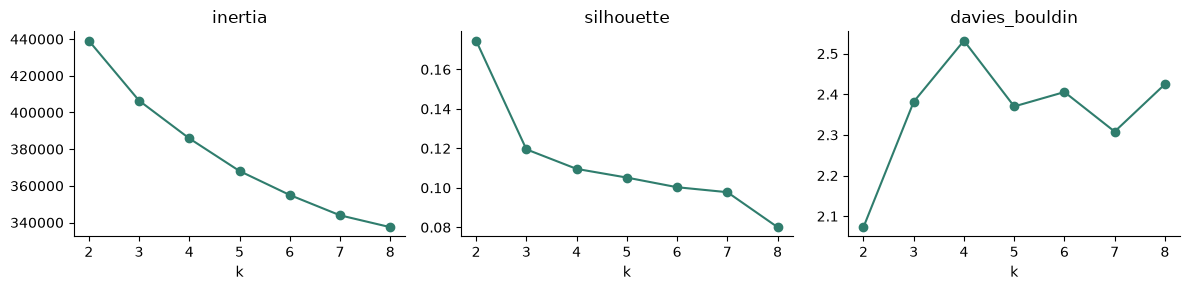

,inertia,silhouette,davies_bouldin
2,439137.602,0.175,2.073
3,406460.048,0.120,2.381
4,385850.254,0.110,2.532
5,368067.276,0.105,2.370
6,354996.728,0.100,2.406
7,343921.963,0.098,2.308
8,337454.847,0.080,2.425


In [4]:
rows = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=0).fit(X, sample_weight=w)
    rows[k] = {
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_, sample_size=10000, random_state=0),
        "davies_bouldin": davies_bouldin_score(X, km.labels_),
    }
kmeans_scores = pd.DataFrame(rows).T

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, kmeans_scores.columns):
    ax.plot(kmeans_scores.index, kmeans_scores[col], marker="o", color="#2F7D6D")
    ax.set_title(col)
    ax.set_xlabel("k")
fig.tight_layout()
fig.savefig(FIGS / "12_kmeans_scores.png", bbox_inches="tight", dpi=150)
plt.show()
kmeans_scores.round(3)

# 3.4) Gaussian mixture (EM)
The generative version of the same idea. Each cluster is a Gaussian, fitted with EM, and BIC picks the number of components (lower is better).

In [5]:
bic = {k: GaussianMixture(n_components=k, random_state=0).fit(X).bic(X) for k in range(2, 9)}
pd.Series(bic, name="BIC").round(0).to_frame()

,BIC
2,1658302.0
3,1434792.0
4,1191149.0
5,1092159.0
6,878746.0
7,651580.0
8,556438.0


> **Note:** silhouette is low for every k and best at k = 2, and Davies-Bouldin is also lowest at k = 2. BIC keeps falling as k grows with no clear elbow, so the mixture keeps finding finer splits rather than a natural number of groups. The students sit on a continuum, not in separate clusters.

# 3.5) Profile the clusters (k = 2)
We keep k = 2, the best by silhouette and Davies-Bouldin, and look at who ends up in each cluster.

In [6]:
km = KMeans(n_clusters=2, random_state=0).fit(X, sample_weight=w)
df["cluster"] = km.labels_

def wmean(x, w):
    ok = x.notna()
    return np.average(x[ok], weights=w[ok])

prof = {}
for c, d in df.groupby("cluster"):
    prof[c] = {
        "share_%": d["SENWT"].sum() / df["SENWT"].sum() * 100,
        "below_L2_%": np.mean([wmean(d[b], d["SENWT"]) for b in BELOW]) * 100,
        "maths": np.mean([wmean(d[p], d["SENWT"]) for p in PV]),
        "ESCS": wmean(d["ESCS"], d["SENWT"]),
        "MATHEFF": wmean(d["MATHEFF"], d["SENWT"]),
        "private_%": wmean(d["SCHL_PRIVATE"], d["SENWT"]) * 100,
        "EDUSHORT": wmean(d["EDUSHORT"], d["SENWT"]),
    }
profile = pd.DataFrame(prof).T
profile.round(2)

,share_%,below_L2_%,maths,ESCS,MATHEFF,private_%,EDUSHORT
0,56.11,57.29,412.35,0.27,-0.26,43.01,-0.4
1,43.89,86.20,356.01,-1.63,-0.89,4.96,1.2


In [7]:
# which systems end up in each cluster (% of each system's students)
pd.crosstab(df["CNT"], df["cluster"], normalize="index").mul(100).loc[SYSTEMS].round(0)

cluster,0,1
CNT,,
ARE,92.0,8.0
SAU,70.0,30.0
QAT,91.0,9.0
JOR,40.0,60.0
MAR,15.0,85.0
PSE,30.0,70.0


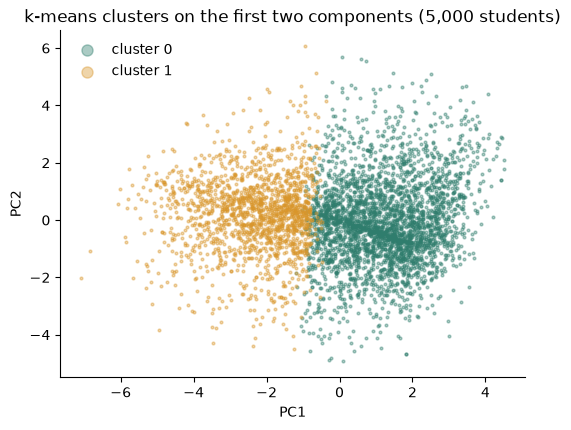

In [8]:
sample = np.random.default_rng(0).choice(len(X), 5000, replace=False)
xy = pca.transform(X[sample])[:, :2]
fig, ax = plt.subplots(figsize=(6, 4.5))
for c, colour in [(0, "#2F7D6D"), (1, "#D9962B")]:
    pts = xy[km.labels_[sample] == c]
    ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.4, color=colour, label=f"cluster {c}")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(frameon=False, markerscale=4)
ax.set_title("k-means clusters on the first two components (5,000 students)")
fig.savefig(FIGS / "13_clusters_pca.png", bbox_inches="tight", dpi=150)
plt.show()

# 3.6) Clustering summary

- **No strong cluster structure.** Silhouette stays low for every k and BIC never levels off. In the PCA plot the two k-means clusters are one continuous cloud cut in half, with no gap between them.
- **The split that k-means finds is advantage vs disadvantage.** One cluster is richer, more confident and more often in private schools. It's mostly UAE and Qatar students, and far fewer of them are below Level 2. The other is mostly Jordan, Morocco and Palestine.
- So clusters mainly rediscover ESCS and the system. We report them as **description** in the Dataset section, not as model features.
- For the generative-vs-discriminative comparison in R3, the GMM fitted here sits next to naive Bayes as the second generative method.

Next: `04_folds.ipynb`.